# 条件数はなぜ数値計算の難しさを表すのか

## 概要

条件数は、入力の相対誤差が出力の相対誤差にどれだけ増幅され得るかを表す。本記事では連立一次方程式の誤差評価を導き、特異値、誤差の方向、残差と解の誤差の違いをPythonで確認する。ここでいう難しさは精度の確保に関するものである。

## 準備

### 実行環境

仮想環境は `wa-src(3.14.6)`、Pythonは `3.14.6` である。ライブラリのバージョンは次のセルに表示する。

セルは上から実行する。小数は有効数字3桁で表示し、計算中は丸めない。グラフはSVGとして埋め込み、作業ディレクトリの `figures` に保存する。

In [1]:
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline

# 指定したバージョンの仮想環境で実行していることを確認する。
assert sys.version_info[:3] == (3, 14, 6)
assert sys.prefix != sys.base_prefix
print(f"実行環境: wa-src({sys.version.split()[0]})")
print(f"Python実行ファイル: {sys.executable}")
print(f"NumPy: {np.__version__}, Matplotlib: {matplotlib.__version__}")

# 配列の数値とグラフの目盛を、表示時だけ有効数字3桁に整える。
np.set_printoptions(formatter={"float_kind": lambda value: f"{value:.2e}"})
tick_formatter = FuncFormatter(lambda value, position: f"{value:#.3g}")
set_matplotlib_formats("svg")
plt.rcParams.update({
    "figure.figsize": (7, 4),
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.250,
    "savefig.format": "svg",
    "svg.fonttype": "none",
})
figure_dir = Path("figures")
figure_dir.mkdir(parents=True, exist_ok=True)


def latex_number(value):
    """数値を有効数字3桁のLaTeX表記に変換する。"""
    mantissa, exponent = f"{float(value):.2e}".split("e")
    return rf"{mantissa}\times 10^{{{int(exponent)}}}"


def save_figure(fig, filename):
    """目盛の表記を整え、SVG保存とノートブック表示を行う。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if axis.get_scale() == "linear":
                axis.set_major_formatter(tick_formatter)
            # 対数軸は整数の指数で表示し、補助目盛の数値を隠す。
            axis.set_minor_formatter(NullFormatter())
    output_path = figure_dir / filename
    fig.savefig(output_path, format="svg", bbox_inches="tight")
    print(f"SVG保存先: {output_path.as_posix()}")
    plt.show()

実行環境: wa-src(3.14.6)
Python実行ファイル: /Users/hiroshi/private/wa_src/.venv/bin/python
NumPy: 2.5.4, Matplotlib: 3.11.2


## 1. 相対誤差から条件数を導く

実数の正則な正方行列について $\mathbf{A}\mathbf{x}=\mathbf{b}$、$\mathbf{b}\ne\mathbf{0}$ とする。以下ではベクトルの長さと行列の大きさを2ノルムで測る。

$$
\|\mathbf{v}\|_2=\sqrt{\sum_i v_i^2},\qquad
\|\mathbf{A}\|_2=\max_{\mathbf{v}\ne\mathbf{0}}
\frac{\|\mathbf{A}\mathbf{v}\|_2}{\|\mathbf{v}\|_2}.
$$

まず行列を固定し、右辺に変化 $\Delta\mathbf{b}$ を加える。変化後の解との差を $\Delta\mathbf{x}$ とおくと、

$$
\begin{aligned}
\mathbf{A}(\mathbf{x}+\Delta\mathbf{x})&=\mathbf{b}+\Delta\mathbf{b},\\
\mathbf{A}\mathbf{x}+\mathbf{A}\Delta\mathbf{x}&=\mathbf{b}+\Delta\mathbf{b},\\
\mathbf{A}\Delta\mathbf{x}&=\Delta\mathbf{b},\\
\Delta\mathbf{x}&=\mathbf{A}^{-1}\Delta\mathbf{b},\\
\|\Delta\mathbf{x}\|_2&\le\|\mathbf{A}^{-1}\|_2\|\Delta\mathbf{b}\|_2.
\end{aligned}
$$

さらに $\|\mathbf{b}\|_2=\|\mathbf{A}\mathbf{x}\|_2\le\|\mathbf{A}\|_2\|\mathbf{x}\|_2$ より、相対誤差は次のように評価できる。

$$
\begin{aligned}
\frac{\|\Delta\mathbf{x}\|_2}{\|\mathbf{x}\|_2}
&\le\frac{\|\mathbf{A}^{-1}\|_2\|\Delta\mathbf{b}\|_2}{\|\mathbf{x}\|_2}\\
&\le\|\mathbf{A}^{-1}\|_2\|\mathbf{A}\|_2
\frac{\|\Delta\mathbf{b}\|_2}{\|\mathbf{b}\|_2}.
\end{aligned}
$$

この係数が行列の条件数である。

$$
\boxed{\kappa_2(\mathbf{A})=\|\mathbf{A}\|_2\|\mathbf{A}^{-1}\|_2},\qquad
\frac{\|\Delta\mathbf{x}\|_2}{\|\mathbf{x}\|_2}
\le\kappa_2(\mathbf{A})\frac{\|\Delta\mathbf{b}\|_2}{\|\mathbf{b}\|_2}.
$$

この評価は右辺だけの有限の変化にも成り立つ。条件数は右辺と誤差の方向を選んだ最悪の場合の増幅率である。[Driscoll・Braunの教科書](https://fncbook.com/condition-number/)にもこの評価がある。

## 2. 特異値と図形の変形

特異値分解を $\mathbf{A}=\mathbf{U}\mathbf{\Sigma}\mathbf{V}^{\mathsf T}$ とする。$\mathbf{U},\mathbf{V}$ は直交行列で、長さを変えない。$\mathbf{\Sigma}$ は正の特異値を対角成分に持つ。最大値を $\sigma_{\max}$、最小値を $\sigma_{\min}$ とすると、

$$
\begin{aligned}
\|\mathbf{A}\|_2&=\sigma_{\max},\\
\mathbf{A}^{-1}&=\mathbf{V}\mathbf{\Sigma}^{-1}\mathbf{U}^{\mathsf T},\\
\|\mathbf{A}^{-1}\|_2&=\max_i\frac{1}{\sigma_i}=\frac{1}{\sigma_{\min}},\\
\kappa_2(\mathbf{A})&=\frac{\sigma_{\max}}{\sigma_{\min}}\ge1.
\end{aligned}
$$

2次元では単位円が楕円に移り、長半径と短半径が特異値に対応する。短い方向を復元するとき、逆行列は $1/\sigma_{\min}$ 倍に拡大する。条件数は長短の半径の比である。特異な行列の条件数は無限大とする。

### Pythonによる計算例

`np.linalg.cond` は既定で特異値分解から2ノルムの条件数を計算する。[NumPy公式資料](https://numpy.org/doc/stable/reference/generated/numpy.linalg.cond.html)

特異値（降順）
array([1.00e+00, 1.00e-02])


<IPython.core.display.Math object>

SVG保存先: figures/01_circle_and_ellipses.svg


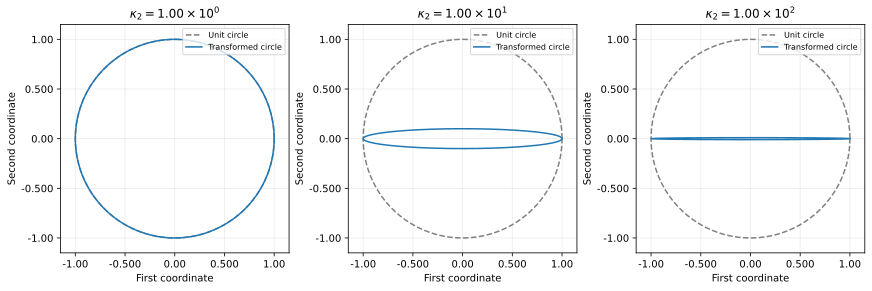

In [2]:
# 対角行列では特異値が対角成分の絶対値になる。
A = np.diag([1, 0.0100])
singular_values = np.linalg.svd(A, compute_uv=False)
kappa = np.linalg.cond(A)
print("特異値（降順）")
pprint(singular_values)
display(Math(
    rf"\kappa_2(\mathbf{{A}})="
    rf"\frac{{{latex_number(singular_values[0])}}}"
    rf"{{{latex_number(singular_values[-1])}}}={latex_number(kappa)}"
))

# 同じ単位円を、異なる条件数の行列で変換する。
theta = np.linspace(0, 2 * np.pi, 721)
unit_circle = np.vstack([np.cos(theta), np.sin(theta)])
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, alpha in zip(axes, [1, 0.100, 0.0100]):
    matrix = np.diag([1, alpha])
    ellipse = matrix @ unit_circle
    ax.plot(*unit_circle, "--", color="gray", label="Unit circle")
    ax.plot(*ellipse, color="tab:blue", label="Transformed circle")
    ax.set(
        xlabel="First coordinate", ylabel="Second coordinate",
        xlim=(-1.15, 1.15), ylim=(-1.15, 1.15),
        title=rf"$\kappa_2={latex_number(np.linalg.cond(matrix))}$",
    )
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=8)
save_figure(fig, "01_circle_and_ellipses.svg")

## 3. 誤差が条件数倍になる例

$0<\alpha\le1$、$\eta>0$ として次の問題を考える。

$$
\mathbf{A}=\begin{bmatrix}1&0\\0&\alpha\end{bmatrix},\quad
\mathbf{b}=\begin{bmatrix}1\\0\end{bmatrix},\quad
\Delta\mathbf{b}=\begin{bmatrix}0\\\eta\end{bmatrix}.
$$

第1式は $x_1=1$、第2式は $\alpha x_2=0$ である。変化後の第2式は $\alpha(x_2+\Delta x_2)=\eta$ になるため、

$$
\mathbf{x}=\begin{bmatrix}1\\0\end{bmatrix},\quad
\Delta\mathbf{x}=\begin{bmatrix}0\\\eta/\alpha\end{bmatrix},\quad
\frac{\|\Delta\mathbf{x}\|_2}{\|\mathbf{x}\|_2}
=\frac{\eta}{\alpha}=\kappa_2(\mathbf{A})\eta.
$$

$\alpha=1.00\times10^{-3}$、$\eta=1.00\times10^{-6}$ なら、入力の相対誤差が $1.00\times10^{-6}$、解の相対誤差が $1.00\times10^{-3}$ になる。入力に人工的な誤差を加えて増幅率を測る。逆行列は説明に用いるだけで、計算には `solve` を使う。

In [3]:
alpha = 1.00e-3
eta = 1.00e-6
A = np.diag([1, alpha])
b = np.array([1, 0], dtype=float)
delta_b = np.array([0, eta])
x = np.linalg.solve(A, b)
x_changed = np.linalg.solve(A, b + delta_b)
input_error = np.linalg.norm(delta_b) / np.linalg.norm(b)
solution_error = np.linalg.norm(x_changed - x) / np.linalg.norm(x)

print("元の解と変化後の解（行ごと）")
pprint(np.vstack([x, x_changed]))
# 辞書内の数値も有効数字3桁に整えてpprintで表示する。
pprint({
    "input_relative_error": f"{input_error:.2e}",
    "solution_relative_error": f"{solution_error:.2e}",
    "amplification": f"{solution_error / input_error:.2e}",
})
display(Math(
    rf"\kappa_2(\mathbf{{A}})\eta="
    rf"{latex_number(np.linalg.cond(A) * input_error)}"
))

元の解と変化後の解（行ごと）
array([[1.00e+00, 0.00e+00],
       [1.00e+00, 1.00e-03]])
{'amplification': '1.00e+03',
 'input_relative_error': '1.00e-06',
 'solution_relative_error': '1.00e-03'}


<IPython.core.display.Math object>

誤差を $\Delta\mathbf{b}=\eta(\cos\theta,\sin\theta)^{\mathsf T}$ とすると、解の変化は $\eta(\cos\theta,\sin\theta/\alpha)^{\mathsf T}$ である。相対誤差の比は次式になる。

$$
\frac{\|\Delta\mathbf{x}\|_2/\|\mathbf{x}\|_2}
{\|\Delta\mathbf{b}\|_2/\|\mathbf{b}\|_2}
=\sqrt{\cos^2\theta+\frac{\sin^2\theta}{\alpha^2}}.
$$

$\theta=0$ では1倍、$\theta=\pi/2$ では $1/\alpha$ 倍となり、方向で結果が異なる。

SVG保存先: figures/02_direction_and_amplification.svg


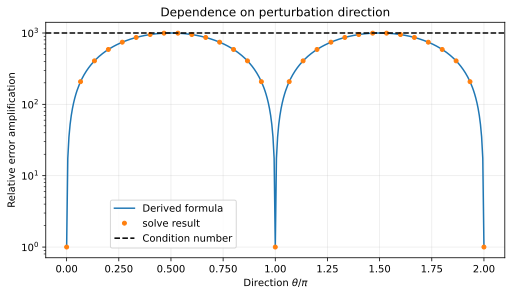

In [4]:
# 同じ大きさの入力誤差を回転させ、増幅率を比較する。
angles = np.linspace(0, 2 * np.pi, 361)
amplifications = []
for angle in angles:
    perturbation = eta * np.array([np.cos(angle), np.sin(angle)])
    perturbed_x = np.linalg.solve(A, b + perturbation)
    relative_change = np.linalg.norm(perturbed_x - x) / np.linalg.norm(x)
    amplifications.append(relative_change / eta)

direction_formula = np.sqrt(np.cos(angles)**2 + np.sin(angles)**2 / alpha**2)
fig, ax = plt.subplots(layout="constrained")
ax.semilogy(angles / np.pi, direction_formula, label="Derived formula")
ax.semilogy(
    angles[::12] / np.pi, np.array(amplifications)[::12],
    "o", markersize=4, label="solve result",
)
ax.axhline(np.linalg.cond(A), color="black", linestyle="--", label="Condition number")
ax.set(xlabel=r"Direction $\theta/\pi$", ylabel="Relative error amplification",
       title="Dependence on perturbation direction")
ax.legend(loc="lower left", bbox_to_anchor=(0.130, 0.0200))
save_figure(fig, "02_direction_and_amplification.svg")

各行: 条件数、入力相対誤差、解の相対誤差
array([[1.00e+00, 1.00e-08, 1.00e-08],
       [1.00e+04, 1.00e-08, 1.00e-04],
       [1.00e+08, 1.00e-08, 1.00e+00],
       [1.00e+12, 1.00e-08, 1.00e+04]])


SVG保存先: figures/03_condition_number_and_error.svg


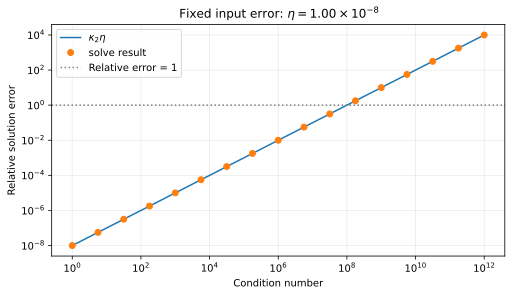

In [5]:
# 入力誤差を固定し、最も増幅される方向で条件数との関係を調べる。
eta_sweep = 1.00e-8
alphas = np.logspace(0, -12, 49)
condition_numbers = []
relative_errors = []
for alpha_value in alphas:
    matrix = np.diag([1, alpha_value])
    changed = np.linalg.solve(matrix, b + np.array([0, eta_sweep]))
    condition_numbers.append(np.linalg.cond(matrix))
    relative_errors.append(np.linalg.norm(changed - x) / np.linalg.norm(x))
condition_numbers = np.array(condition_numbers)
relative_errors = np.array(relative_errors)

print("各行: 条件数、入力相対誤差、解の相対誤差")
pprint(np.column_stack([
    condition_numbers[::16], np.full(4, eta_sweep), relative_errors[::16],
]))
fig, ax = plt.subplots(layout="constrained")
ax.loglog(condition_numbers, condition_numbers * eta_sweep, label=r"$\kappa_2\eta$")
ax.loglog(condition_numbers[::3], relative_errors[::3], "o", label="solve result")
ax.axhline(1, color="gray", linestyle=":", label="Relative error = 1")
ax.set(xlabel="Condition number", ylabel="Relative solution error",
       title="Fixed input error: " + rf"$\eta={latex_number(eta_sweep)}$")
ax.legend()
save_figure(fig, "03_condition_number_and_error.svg")

## 4. 行列式の大きさだけでは判断できない

$c\ne0$ を掛けても条件数は変わらない。一方、$n$ 次行列の行列式は $c^n$ 倍になる。

$$
\begin{aligned}
\kappa_2(c\mathbf{A})
&=\|c\mathbf{A}\|_2\|(c\mathbf{A})^{-1}\|_2\\
&=|c|\|\mathbf{A}\|_2\frac{1}{|c|}\|\mathbf{A}^{-1}\|_2
=\kappa_2(\mathbf{A}),\\
\det(c\mathbf{A})&=c^n\det(\mathbf{A}).
\end{aligned}
$$

小さな行列式だけで相対誤差への敏感さは判断できない。図では行列全体の倍率を変え、条件数と行列式を比較する。

SVG保存先: figures/04_scaling_and_determinant.svg


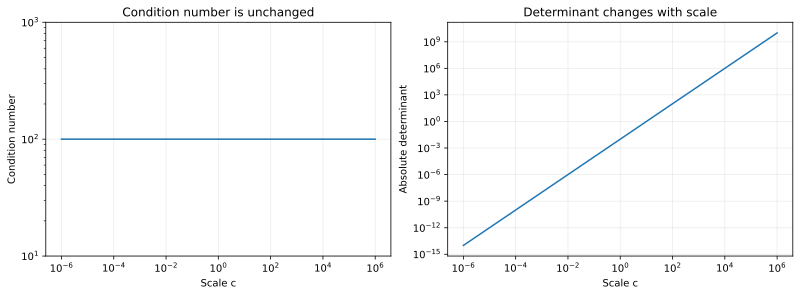

In [6]:
base_matrix = np.diag([1, 0.0100])
scales = np.logspace(-6, 6, 49)
scaled_conditions = np.array([np.linalg.cond(c * base_matrix) for c in scales])
scaled_determinants = np.array([abs(np.linalg.det(c * base_matrix)) for c in scales])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
# 定数系列の自動範囲計算を避けるため、描画前に縦軸の範囲を指定する。
axes[0].set(xscale="log", yscale="log", ylim=(10, 1000))
axes[0].plot(scales, scaled_conditions)
axes[0].set(xlabel="Scale c", ylabel="Condition number",
            title="Condition number is unchanged")
axes[1].loglog(scales, scaled_determinants)
axes[1].set(xlabel="Scale c", ylabel="Absolute determinant",
            title="Determinant changes with scale")
save_figure(fig, "04_scaling_and_determinant.svg")

## 5. 残差と計算方法の安定性

近似解を $\widehat{\mathbf{x}}$ とし、残差を $\mathbf{r}=\mathbf{b}-\mathbf{A}\widehat{\mathbf{x}}$ と定義する。

$$
\begin{aligned}
\mathbf{r}&=\mathbf{A}\mathbf{x}-\mathbf{A}\widehat{\mathbf{x}}
=\mathbf{A}(\mathbf{x}-\widehat{\mathbf{x}}),\\
\mathbf{x}-\widehat{\mathbf{x}}&=\mathbf{A}^{-1}\mathbf{r},\\
\frac{\|\mathbf{x}-\widehat{\mathbf{x}}\|_2}{\|\mathbf{x}\|_2}
&\le\kappa_2(\mathbf{A})\frac{\|\mathbf{r}\|_2}{\|\mathbf{b}\|_2}.
\end{aligned}
$$

第3節の行列と右辺で、近似解を意図的に $\widehat{\mathbf{x}}=(1,1)^{\mathsf T}$ と置く。このとき $\mathbf{r}=(0,-\alpha)^{\mathsf T}$ なので、相対残差は $\alpha$ だが、解の相対誤差は1である。小さな残差だけでは解の精度を保証できない。

各行: 条件数、相対残差、解の相対誤差
array([[1.00e+00, 1.00e+00, 1.00e+00],
       [1.00e+04, 1.00e-04, 1.00e+00],
       [1.00e+08, 1.00e-08, 1.00e+00],
       [1.00e+12, 1.00e-12, 1.00e+00]])
SVG保存先: figures/05_residual_and_solution_error.svg


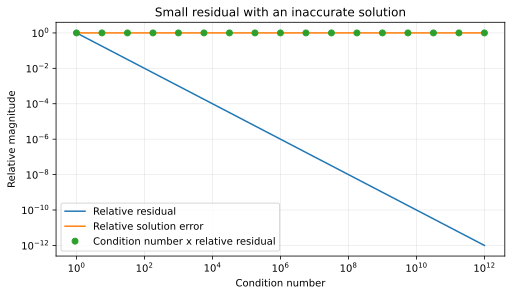

In [7]:
# solveの出力ではなく、残差と誤差の違いを示すために作った近似解である。
x_hat = np.array([1, 1], dtype=float)
relative_residuals = []
forward_errors = []
for alpha_value in alphas:
    matrix = np.diag([1, alpha_value])
    residual = b - matrix @ x_hat
    relative_residuals.append(np.linalg.norm(residual) / np.linalg.norm(b))
    forward_errors.append(np.linalg.norm(x_hat - x) / np.linalg.norm(x))
relative_residuals = np.array(relative_residuals)
forward_errors = np.array(forward_errors)

print("各行: 条件数、相対残差、解の相対誤差")
pprint(np.column_stack([
    condition_numbers[::16], relative_residuals[::16], forward_errors[::16],
]))
fig, ax = plt.subplots(layout="constrained")
ax.loglog(condition_numbers, relative_residuals, label="Relative residual")
ax.loglog(condition_numbers, forward_errors, label="Relative solution error")
ax.loglog(
    condition_numbers[::3], (condition_numbers * relative_residuals)[::3],
    "o", label="Condition number x relative residual",
)
ax.set(xlabel="Condition number", ylabel="Relative magnitude",
       title="Small residual with an inaccurate solution")
ax.legend()
save_figure(fig, "05_residual_and_solution_error.svg")

$\mathbf{A}\widehat{\mathbf{x}}=\mathbf{b}-\mathbf{r}$ なので、相対残差は「行列を固定したまま、近似解を厳密な解にするために右辺を変える割合」でもある。これは右辺だけを変える後退誤差であり、解の相対誤差は前進誤差である。

後退安定な方法は、入力をわずかに変えた問題の厳密解を返す。しかし条件数が大きければ、そのわずかな変化も解では大きくなり得る。条件数は問題の性質であり、安定性は計算方法の性質である。

右辺の相対誤差を $10^{-p}$、条件数を $10^q$ とすると、上の評価は $10^{q-p}$ となる。最悪の場合、約 $q$ 桁の精度が失われ得るという目安であり、実際の損失桁数の断定ではない。測定時の入力誤差は、計算精度を上げるだけでは取り除けない。

## 結論

この記事では、条件数が入力の相対誤差に対する解の相対誤差の最大増幅率を表すことを説明した。

条件数は最大特異値と最小特異値の比である。実際の増幅率は誤差の方向で変わる。精度の評価には、残差、条件数、入力の精度、計算方法の安定性の確認が必要である。